# Day 35 | Check RAG Answers and Summaries

**KGP Talkie**

Test retrieval, evidence, missing answers, and short document reports.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

The supplied course uses these v1 interfaces. We keep their version notices out of the classroom display; real input, validation, and server errors still appear.

In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*langchain-community.*sunset.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="The class `InMemoryChatMessageHistory` was deprecated.*")

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [3]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [4]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

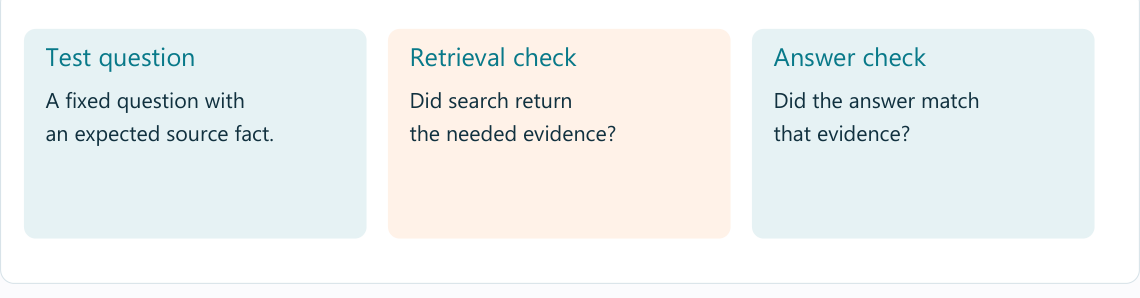

Document keeps text and source details. OllamaEmbeddings returns vectors, not chat replies.

In [5]:
from langchain_core.documents import Document
from langchain_ollama import OllamaEmbeddings

FAISS stores vectors and finds nearby vectors. Its result is linked back to source text.

In [6]:
from langchain_community.vectorstores import FAISS

One fact per line keeps the first search example easy to inspect.

In [7]:
lines = (ASSETS / "course-notes.txt").read_text(encoding="utf-8").splitlines()

enumerate gives a line position. The list creates one Document per line and keeps an evidence label.

In [8]:
docs = [Document(page_content=line, metadata={"source": "course-notes.txt", "line": i + 1}) for i, line in enumerate(lines)]

Use the same downloaded embedding model for stored facts and questions.

In [9]:
embeddings = OllamaEmbeddings(model="nomic-embed-text", base_url="http://localhost:11434")

Embed each document and build this notebook's own index. No previous day is required.

In [10]:
store = FAISS.from_documents(docs, embeddings)

ChatOllama sends chat requests to the local Ollama server.

In [11]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [12]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [13]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

A chat prompt template fills named inputs and keeps message roles.

In [14]:
from langchain_core.prompts import ChatPromptTemplate

This parser reads reply content and returns a plain Python string.

In [15]:
from langchain_core.output_parsers import StrOutputParser

In [16]:
retriever = store.as_retriever(search_kwargs={"k": 3})

Format retrieved documents as labeled evidence. Keep the question separate from this text.

In [17]:
def read_context(question):
    found = retriever.invoke(question)
    return "\n".join(f"Line {doc.metadata['line']}: {doc.page_content}" for doc in found)

In [18]:
prompt = ChatPromptTemplate.from_messages([("system", "Answer from the supplied evidence only. If the fact is missing, say not provided. State the evidence line."), ("human", "Evidence:\n{context}\nQuestion: {question}")])

In [19]:
chain = prompt | llm | StrOutputParser()

In [20]:
question = "When is Python class?"
context = read_context(question)
print(context)

Line 1: Python class is on Monday at 10:00 in Room 2.
Line 2: Pandas class is on Tuesday at 11:00 in Room 3.
Line 3: Bring a laptop to both classes.


In [21]:
print(chain.invoke({"context": context, "question": question}))

According to Line 1, the Python class is on Monday at 10:00 in Room 2.


Known answers come from the source. An expected-word check is a simple aid, not a complete quality metric.

In [22]:
tests = [("When is Python class?", "Monday", "10:00"), ("When is Pandas class?", "Tuesday", "11:00"), ("What is the fee?", "not provided", "")]

In [23]:
for question, expected, time in tests:
    context = read_context(question)
    answer = chain.invoke({"context": context, "question": question})
    print({"question": question, "context": context, "answer": answer, "expected_words_present": expected.lower() in answer.lower() and time in answer})

{'question': 'When is Python class?', 'context': 'Line 1: Python class is on Monday at 10:00 in Room 2.\nLine 2: Pandas class is on Tuesday at 11:00 in Room 3.\nLine 3: Bring a laptop to both classes.', 'answer': 'According to Line 1, the Python class is on Monday at 10:00 in Room 2.', 'expected_words_present': True}


{'question': 'When is Pandas class?', 'context': 'Line 2: Pandas class is on Tuesday at 11:00 in Room 3.\nLine 1: Python class is on Monday at 10:00 in Room 2.\nLine 3: Bring a laptop to both classes.', 'answer': 'Pandas class is on Tuesday at 11:00 in Room 3. (Line 2)', 'expected_words_present': True}


{'question': 'What is the fee?', 'context': 'Line 4: The class notes do not give a fee.\nLine 3: Bring a laptop to both classes.\nLine 2: Pandas class is on Tuesday at 11:00 in Room 3.', 'answer': 'Not provided. (Line 4)', 'expected_words_present': True}


A broad summary reads all four short facts, rather than a narrow retrieved subset.

In [24]:
all_text = "\n".join(lines)
print(llm.invoke(f"Summarize all these notes in three points. Do not add facts: {all_text}").content)

Here are three key points:

1. Class schedule
2. Required materials (laptop)
3. No fee mentioned


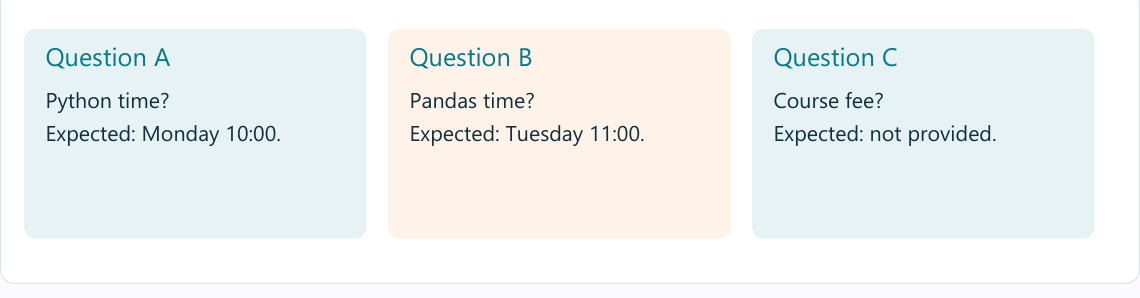

## Try a fresh input

Summarize all short notes, then check each bullet against its source section.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-rag).